# Lab 5 VAE Experiments 2, 3 and 4: Fashion MNIST

This notebook continues the Fashion MNIST VAE experiments.

The experiments carried out are:

1. Compare `latent_dim = 2`, `3`, `4`, and `5`.
2. Evaluate reconstruction loss, generated samples and latent-dimension activity.
3. Select `latent_dim = 3` as a balanced and interpretable setting.
4. Train the main Fashion MNIST VAE using `latent_dim = 3`.
5. Test how different latent-space scale values affect image generation.
6. Generate class-centre prototypes for all 10 Fashion MNIST classes.
7. Save the trained `latent_dim = 3` model weights for later use.

## Methodology

This notebook changes one variable at a time to make the experiment easier to interpret.

First, different latent dimensions are compared to select the most suitable tested value. After `latent_dim = 3` is selected, the main model keeps this latent dimension fixed while other experiments, such as scale testing and class-centre generation, are carried out.

This helps ensure that differences in the results can be linked to the specific experiment being tested.

# 1. Control GPU memory usage.

In [1]:
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# 2. Import libraries

In [2]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt
import pandas as pd
import gc

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

# 3. Sampling Layer

## This is to generate values according to the standard normal distribution, for neurons in the latent layer.

The Sampling layer uses `z_mean` and `z_log_var` to create the sampled latent vector `z`. This allows the VAE to learn a smooth and continuous latent space.


In [3]:
class Sampling(layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# 4. Additional Comparison: Testing Different Latent Dimensions

Before choosing the main VAE latent dimension, a quick comparison is carried out using different latent dimensions: `2`, `3`, `4`, and `5`.

This is done because Experiment 1 showed that `latent_dim = 2` was too limited for Fashion MNIST. However, increasing the latent dimension does not automatically mean the model is better. If too many latent dimensions are used, some dimensions may not contribute much.

Therefore, this comparison checks:

1. Whether reconstruction loss improves as latent dimension changes.
2. Whether generated samples improve.
3. Whether the latent dimensions show meaningful spread using violin plots.

This comparison uses shorter training than the final model, so it is used only as supporting analysis. A balanced and interpretable latent dimension will then be selected for the main VAE model using the combined evidence.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
import gc

# Load Fashion MNIST
(x_train_cmp, y_train_cmp), (x_test_cmp, y_test_cmp) = tf.keras.datasets.fashion_mnist.load_data()

# Normalise and reshape
x_train_cmp = np.expand_dims(x_train_cmp, -1).astype("float32") / 255
x_test_cmp = np.expand_dims(x_test_cmp, -1).astype("float32") / 255

fashion_class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

print("x_train_cmp shape:", x_train_cmp.shape)
print("x_test_cmp shape:", x_test_cmp.shape)

x_train_cmp shape: (60000, 28, 28, 1)
x_test_cmp shape: (10000, 28, 28, 1)


# 5. Balanced Subset for Quick Comparison

To keep the comparison faster, a balanced subset of Fashion MNIST is used. This ensures that all 10 classes are represented fairly during the comparison.

In [5]:
def create_balanced_subset(x, y, samples_per_class=2000, seed=42):
    rng = np.random.default_rng(seed)
    selected_indices = []

    for class_id in range(10):
        class_indices = np.where(y == class_id)[0]
        chosen_indices = rng.choice(class_indices, samples_per_class, replace=False)
        selected_indices.extend(chosen_indices)

    selected_indices = np.array(selected_indices)
    rng.shuffle(selected_indices)

    return x[selected_indices], y[selected_indices]


# 2000 samples per class = 20,000 training images
x_train_cmp_small, y_train_cmp_small = create_balanced_subset(
    x_train_cmp,
    y_train_cmp,
    samples_per_class=2000
)

# 300 samples per class = 3,000 images for latent analysis
x_test_cmp_small, y_test_cmp_small = create_balanced_subset(
    x_test_cmp,
    y_test_cmp,
    samples_per_class=300
)

print("Comparison training subset:", x_train_cmp_small.shape)
print("Comparison latent analysis subset:", x_test_cmp_small.shape)

Comparison training subset: (20000, 28, 28, 1)
Comparison latent analysis subset: (3000, 28, 28, 1)


# 6. Build Temporary VAE Models for Comparison

The following helper functions build temporary VAE models for each latent dimension. These models are only used for comparison and do not replace the final main VAE model used later.

In [6]:
class SamplingComparison(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


class VAEComparison(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)

            reconstruction_loss = tf.keras.losses.binary_crossentropy(data, reconstruction)
            reconstruction_loss = tf.reduce_sum(reconstruction_loss, axis=(1, 2))
            reconstruction_loss = tf.reduce_mean(reconstruction_loss)

            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_sum(kl_loss, axis=1)
            kl_loss = tf.reduce_mean(kl_loss)

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }


def build_vae_for_latent_dim(latent_dim):
    # Encoder
    encoder_inputs = keras.Input(shape=(28, 28, 1))

    x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
    x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)

    x = layers.Flatten()(x)
    x = layers.Dense(16, activation="relu")(x)

    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = SamplingComparison()([z_mean, z_log_var])

    encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name=f"encoder_latent_{latent_dim}")

    # Decoder
    latent_inputs = keras.Input(shape=(latent_dim,))

    x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
    x = layers.Reshape((7, 7, 64))(x)

    x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)

    decoder_outputs = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)

    decoder = keras.Model(latent_inputs, decoder_outputs, name=f"decoder_latent_{latent_dim}")

    vae = VAEComparison(encoder, decoder, name=f"vae_latent_{latent_dim}")
    vae.compile(optimizer=keras.optimizers.Adam())

    return encoder, decoder, vae

# 7. Train VAE Models with Different Latent Dimensions

The VAE is trained using `latent_dim = 2`, `3`, `4`, and `5`. Each model is trained with the same architecture and same dataset subset so that the comparison is fair.

A shorter training duration is used for this comparison to reduce runtime. The purpose is to observe the trend, not to replace the final full training.

In [7]:
latent_dims_to_test = [2, 3, 4, 5]
comparison_epochs = 10
comparison_batch_size = 128

comparison_results = []
comparison_z_means = {}
comparison_generated_images = {}

rng = np.random.default_rng(42)

for latent_dim_value in latent_dims_to_test:
    print("=" * 60)
    print(f"Training VAE with latent_dim = {latent_dim_value}")
    print("=" * 60)

    keras.backend.clear_session()
    gc.collect()

    encoder_cmp_model, decoder_cmp_model, vae_cmp_model = build_vae_for_latent_dim(latent_dim_value)

    history = vae_cmp_model.fit(
        x_train_cmp_small,
        epochs=comparison_epochs,
        batch_size=comparison_batch_size,
        verbose=1
    )

    final_loss = history.history["loss"][-1]
    final_reconstruction_loss = history.history["reconstruction_loss"][-1]
    final_kl_loss = history.history["kl_loss"][-1]

    # Extract z_mean for violin plot
    z_mean_cmp, _, _ = encoder_cmp_model.predict(x_test_cmp_small, verbose=0)
    comparison_z_means[latent_dim_value] = z_mean_cmp

    # Generate random samples from the decoder
    random_latent_vectors = rng.normal(size=(8, latent_dim_value))
    generated_images = decoder_cmp_model.predict(random_latent_vectors, verbose=0)
    comparison_generated_images[latent_dim_value] = generated_images

    comparison_results.append({
        "latent_dim": latent_dim_value,
        "final_loss": final_loss,
        "final_reconstruction_loss": final_reconstruction_loss,
        "final_kl_loss": final_kl_loss
    })

comparison_results_df = pd.DataFrame(comparison_results)
comparison_results_df

,latent_dim,final_loss,final_reconstruction_loss,final_kl_loss
0,2,274.497925,266.802734,7.695221
1,3,273.268829,266.782715,6.486112
2,4,259.920227,251.323624,8.596619
3,5,276.089447,266.579803,9.509624


### Loss Comparison Observation

The table below compares the final loss, reconstruction loss, and KL loss for each tested latent dimension. Reconstruction loss is useful for checking how well the model reconstructs Fashion MNIST images.

A lower reconstruction loss suggests better reconstruction. However, the latent dimension should not be selected based only on loss. Generated image quality and whether the latent dimensions are meaningfully used should also be considered.

# 8. Loss Comparison for Different Latent Dimensions

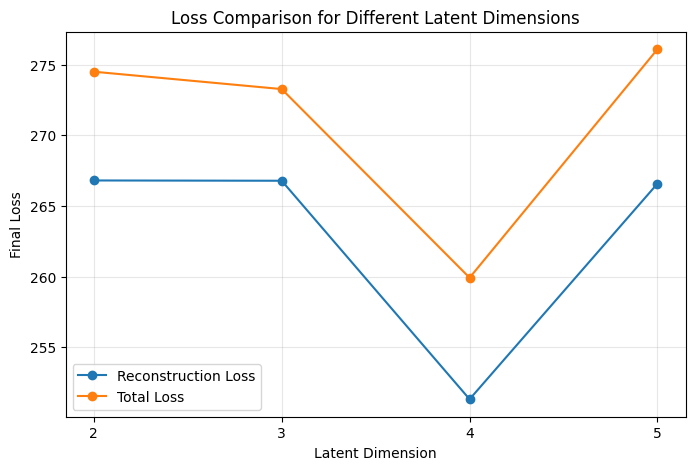

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_results_df["latent_dim"],
    comparison_results_df["final_reconstruction_loss"],
    marker="o",
    label="Reconstruction Loss"
)

plt.plot(
    comparison_results_df["latent_dim"],
    comparison_results_df["final_loss"],
    marker="o",
    label="Total Loss"
)

plt.xticks(comparison_results_df["latent_dim"])
plt.xlabel("Latent Dimension")
plt.ylabel("Final Loss")
plt.title("Loss Comparison for Different Latent Dimensions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 9. Generated Sample Comparison

The images below show random samples generated by each temporary VAE decoder. This helps compare whether increasing the latent dimension improves the variety or clarity of generated Fashion MNIST-like images.

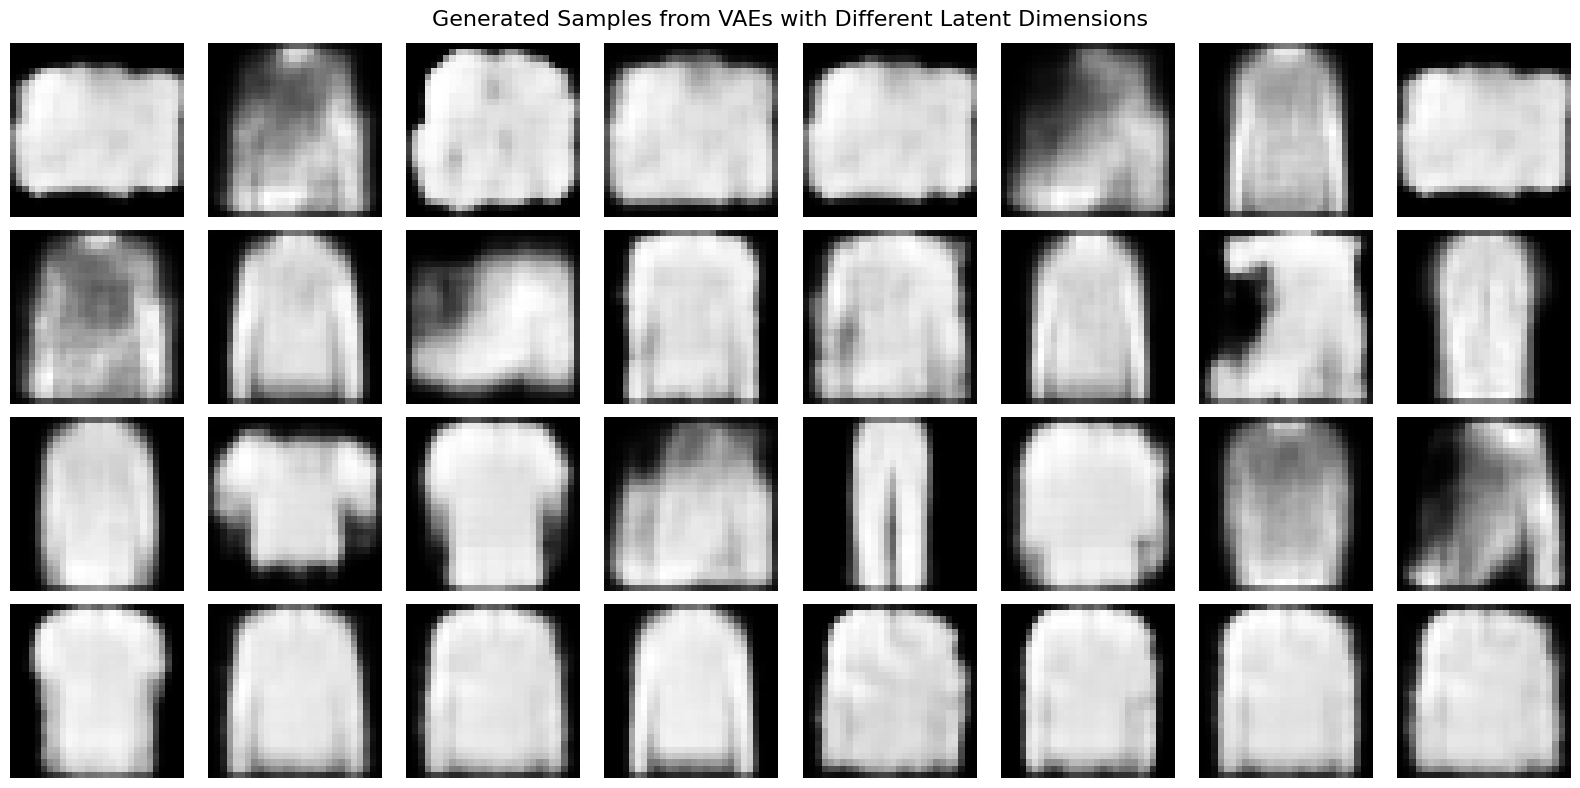

In [9]:
plt.figure(figsize=(16, 8))

plot_index = 1

for row, latent_dim_value in enumerate(latent_dims_to_test):
    generated_images = comparison_generated_images[latent_dim_value]

    for col in range(8):
        plt.subplot(len(latent_dims_to_test), 8, plot_index)
        plt.imshow(generated_images[col].reshape(28, 28), cmap="gray")
        plt.axis("off")

        if col == 0:
            plt.ylabel(f"dim={latent_dim_value}", rotation=0, labelpad=25)

        plot_index += 1

plt.suptitle("Generated Samples from VAEs with Different Latent Dimensions", fontsize=16)
plt.tight_layout()
plt.show()

### Generated Sample Comparison Observation

All four temporary VAEs generated Fashion MNIST-like images after 10 epochs. However, the clarity and category variety differ between individual samples.

No latent dimension clearly dominates based on only eight randomly generated images. The visual comparison should therefore be treated as supporting evidence rather than the main selection criterion.

The latent dimension is selected using the generated samples together with reconstruction loss and latent-dimension activity.

# 10. Violin Plot Comparison for Different Latent Dimensions

The violin plots below show the distribution of `z_mean` values for each tested latent dimension.

The latent values are expected to be mostly centred around 0 because the VAE uses KL loss. Therefore, the key thing to check is the spread of each latent dimension.

If a dimension has a wider spread, it suggests that the model is using that dimension to capture variation. If a dimension is very narrow and close to 0, it may mean that the dimension contributes less.

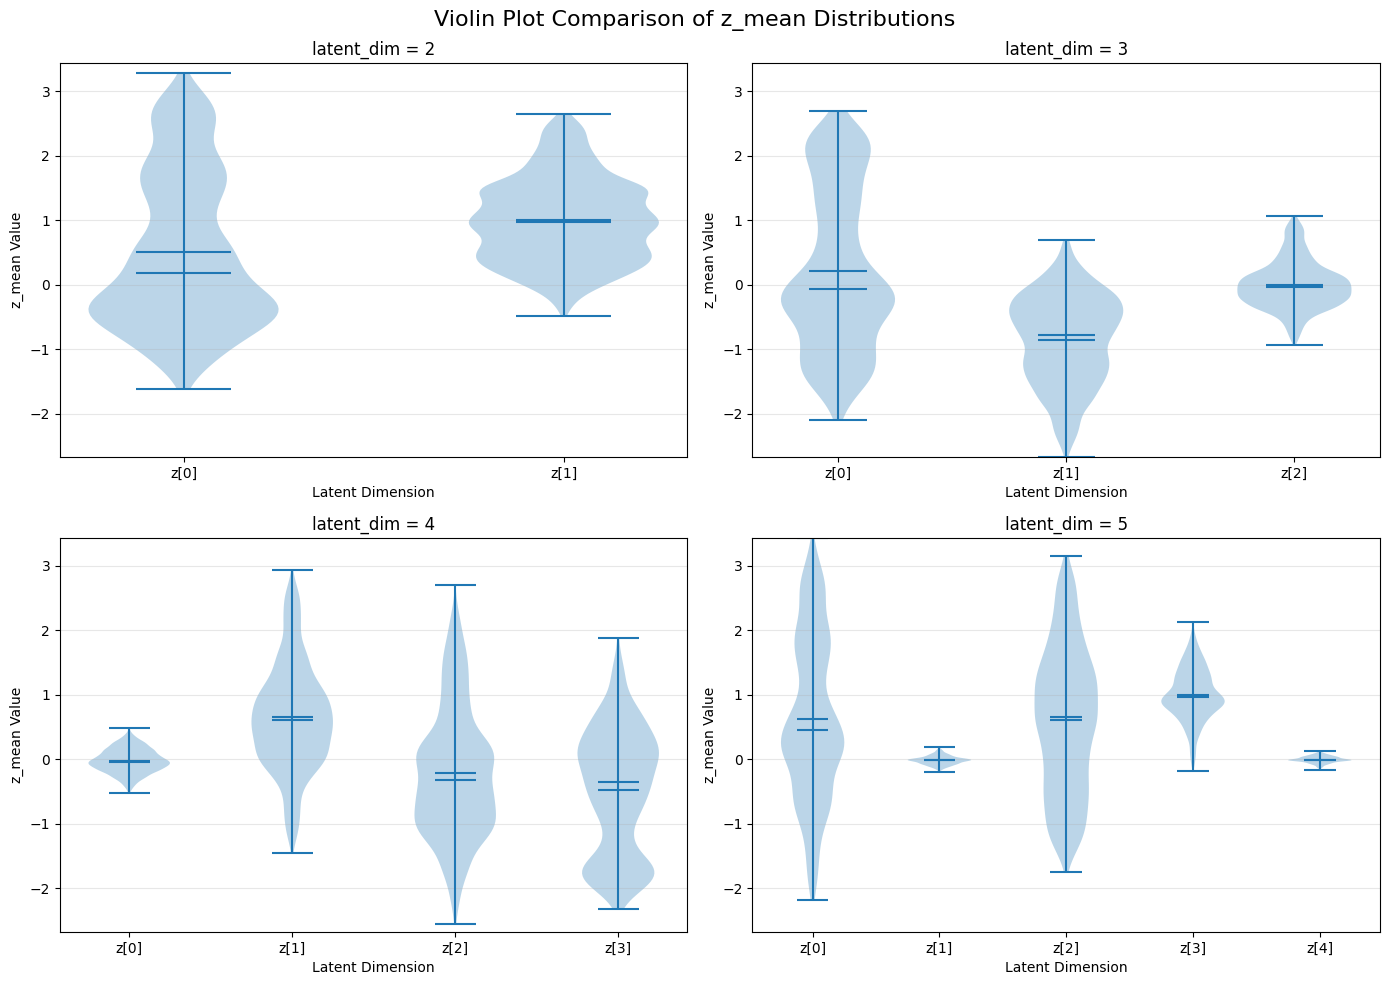

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Use same y-axis scale for fair comparison
all_z_values = np.concatenate([
    comparison_z_means[latent_dim_value].flatten()
    for latent_dim_value in latent_dims_to_test
])

y_min = all_z_values.min()
y_max = all_z_values.max()

for ax, latent_dim_value in zip(axes, latent_dims_to_test):
    z_mean_values = comparison_z_means[latent_dim_value]

    data_to_plot = [
        z_mean_values[:, dim] for dim in range(z_mean_values.shape[1])
    ]

    ax.violinplot(
        data_to_plot,
        showmeans=True,
        showmedians=True
    )

    ax.set_xticks(np.arange(1, z_mean_values.shape[1] + 1))
    ax.set_xticklabels([f"z[{i}]" for i in range(z_mean_values.shape[1])])

    ax.set_ylim(y_min, y_max)

    ax.set_title(f"latent_dim = {latent_dim_value}")
    ax.set_xlabel("Latent Dimension")
    ax.set_ylabel("z_mean Value")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Violin Plot Comparison of z_mean Distributions", fontsize=16)
plt.tight_layout()
plt.show()

### Violin Plot Comparison Observation

The violin plots show that increasing the latent dimension does not guarantee that every additional dimension will be used meaningfully.

For `latent_dim = 2`, both dimensions are active. Their standard deviations are approximately `1.20` and `0.65`.

For `latent_dim = 3`, all three dimensions show meaningful spread. Their standard deviations are approximately `1.24`, `0.70`, and `0.37`.

For `latent_dim = 4`, three dimensions are active, while `z[0]` has a smaller standard deviation of approximately `0.19`, slightly below the activity threshold of `0.20`.

For `latent_dim = 5`, `z[0]`, `z[2]`, and `z[3]` show meaningful spread. However, `z[1]` and `z[4]` remain close to 0 and have standard deviations of approximately `0.07` and `0.05`.

Therefore, increasing the latent dimension gives the model more potential capacity, but the additional dimensions may remain weak or inactive.

The activity threshold of `0.20` is a practical heuristic used for this experiment, not a universal definition of an active latent dimension.

# 11. Latent Dimension Comparison

In [11]:
spread_rows = []

for latent_dim_value in latent_dims_to_test:
    z_mean_values = comparison_z_means[latent_dim_value]

    for dim in range(z_mean_values.shape[1]):
        spread_rows.append({
            "latent_dim": latent_dim_value,
            "dimension": f"z[{dim}]",
            "mean": z_mean_values[:, dim].mean(),
            "std": z_mean_values[:, dim].std(),
            "min": z_mean_values[:, dim].min(),
            "max": z_mean_values[:, dim].max()
        })

spread_df = pd.DataFrame(spread_rows)
spread_df

,latent_dim,dimension,mean,std,min,max
0,2,z[0],0.503729,1.195672,-1.615032,3.287531
1,2,z[1],0.998336,0.654024,-0.491027,2.641550
2,3,z[0],0.204673,1.240792,-2.106483,2.695664
3,3,z[1],-0.858356,0.698797,-2.677142,0.688312
4,3,z[2],-0.003647,0.371946,-0.938039,1.065079
5,4,z[0],-0.028705,0.185050,-0.522425,0.475600
6,4,z[1],0.647557,0.832694,-1.451866,2.940718
7,4,z[2],-0.217492,0.994070,-2.561903,2.694477
8,4,z[3],-0.483509,0.962961,-2.327172,1.882129
9,5,z[0],0.629285,1.256879,-2.180436,3.432588


# 12. Summarise latent dimension activity

In [12]:
# Summarise latent dimension activity

active_threshold = 0.20

latent_activity_summary = (
    spread_df
    .groupby("latent_dim")
    .agg(
        average_std=("std", "mean"),
        max_std=("std", "max"),
        min_std=("std", "min"),
        active_dimensions=("std", lambda x: (x > active_threshold).sum()),
        total_dimensions=("std", "count")
    )
    .reset_index()
)

latent_activity_summary["active_ratio"] = (
    latent_activity_summary["active_dimensions"] / latent_activity_summary["total_dimensions"]
)

latent_activity_summary

,latent_dim,average_std,max_std,min_std,active_dimensions,total_dimensions,active_ratio
0,2,0.924848,1.195672,0.654024,2,2,1.00
1,3,0.770512,1.240792,0.371946,3,3,1.00
2,4,0.743694,0.994070,0.185050,3,4,0.75
3,5,0.580290,1.256879,0.050793,3,5,0.60


# 13. Combine reconstruction loss and latent activity into one comparison table

In [13]:
# Combine reconstruction loss and latent activity into one comparison table

latent_dim_summary = comparison_results_df.merge(
    latent_activity_summary,
    on="latent_dim"
)

latent_dim_summary

,latent_dim,final_loss,final_reconstruction_loss,final_kl_loss,average_std,max_std,min_std,active_dimensions,total_dimensions,active_ratio
0,2,274.497925,266.802734,7.695221,0.924848,1.195672,0.654024,2,2,1.00
1,3,273.268829,266.782715,6.486112,0.770512,1.240792,0.371946,3,3,1.00
2,4,259.920227,251.323624,8.596619,0.743694,0.994070,0.185050,3,4,0.75
3,5,276.089447,266.579803,9.509624,0.580290,1.256879,0.050793,3,5,0.60


### Latent Dimension Comparison Observation

The comparison shows that reconstruction performance and latent-space usage do not always improve together.

`latent_dim = 4` achieved the lowest reconstruction loss of approximately `251.32`, but only three out of four dimensions were classified as active.

`latent_dim = 3` achieved a reconstruction loss of approximately `266.78` and used all three dimensions during the quick comparison.

`latent_dim = 5` did not improve the reconstruction loss substantially and used only three out of five dimensions. `latent_dim = 2` was compact and fully active, but Experiment 1 showed that two dimensions provided limited class separation and generation variety.

Therefore, `latent_dim = 3` was selected as a compact and interpretable compromise. It should not be described as the lowest-loss or universally optimal setting.

# 14. Supporting Ranking of the Tested Latent Dimensions

In [14]:
# Rank the tested latent dimensions

# Lower reconstruction loss is better
latent_dim_summary["reconstruction_loss_rank"] = latent_dim_summary["final_reconstruction_loss"].rank(
    ascending=True
)

# More active dimensions is better
latent_dim_summary["active_dimensions_rank"] = latent_dim_summary["active_dimensions"].rank(
    ascending=False
)

# Higher average spread is better, but not the only factor
latent_dim_summary["average_std_rank"] = latent_dim_summary["average_std"].rank(
    ascending=False
)

# Overall score: lower is better
latent_dim_summary["overall_rank_score"] = (
    latent_dim_summary["reconstruction_loss_rank"]
    + latent_dim_summary["active_dimensions_rank"]
    + latent_dim_summary["average_std_rank"]
)

latent_dim_summary = latent_dim_summary.sort_values("overall_rank_score")

latent_dim_summary

,latent_dim,final_loss,final_reconstruction_loss,final_kl_loss,average_std,max_std,min_std,active_dimensions,total_dimensions,active_ratio,reconstruction_loss_rank,active_dimensions_rank,average_std_rank,overall_rank_score
2,4,259.920227,251.323624,8.596619,0.743694,0.994070,0.185050,3,4,0.75,1.0,2.0,3.0,6.0
1,3,273.268829,266.782715,6.486112,0.770512,1.240792,0.371946,3,3,1.00,3.0,2.0,2.0,7.0
3,5,276.089447,266.579803,9.509624,0.580290,1.256879,0.050793,3,5,0.60,2.0,2.0,4.0,8.0
0,2,274.497925,266.802734,7.695221,0.924848,1.195672,0.654024,2,2,1.00,4.0,4.0,1.0,9.0


### Selection Criteria for the Main Latent Dimension

To choose the most suitable latent dimension, reconstruction loss alone is not enough. A model may have lower loss but may not use its latent dimensions meaningfully.

Therefore, the tested latent dimensions are compared using three criteria:

1. Final reconstruction loss — lower is better.
2. Number of active latent dimensions — more active dimensions means the model is using the latent space more meaningfully.
3. Average standard deviation of `z_mean` — larger spread suggests that the latent dimension captures more variation.

These criteria provide supporting evidence for the selection. The final decision also considers model compactness, active-dimension ratio and how practical the latent space is to interpret.

### Interpretation of the Supporting Rank Score

The unweighted rank score places `latent_dim = 4` first because it achieved a substantially lower reconstruction loss in the quick comparison.

However, this score is only a supporting summary. It does not account fully for model compactness, the proportion of active dimensions, visual interpretability, or the earlier finding that `latent_dim = 2` was too limited.

`latent_dim = 3` is therefore selected manually as a balanced experimental setting because:

1. All three dimensions were active in the quick comparison.
2. It provides more capacity than `latent_dim = 2`.
3. It avoids the weaker or underused dimensions observed in the higher-dimensional models.
4. A three-dimensional space remains practical for pairwise and frozen-dimension analysis.

This is a design decision rather than a claim that `latent_dim = 3` achieved the best value for every metric.

# 15. Conclusion for Latent Dimension Selection

The comparison shows that increasing the latent dimension does not automatically improve the VAE.

In the quick comparison, `latent_dim = 4` achieved the lowest reconstruction loss, but one of its four dimensions fell slightly below the selected activity threshold. `latent_dim = 5` had more capacity, but it had a lower active ratio and did not clearly improve the overall representation. `latent_dim = 2` was compact, but it only had two latent values to represent all 10 Fashion MNIST classes.

`latent_dim = 3` was selected for the main experiment because it had all three dimensions active in the comparison and gave a compact, interpretable latent space. This makes it a suitable balanced choice for further analysis.

Therefore, the main VAE model uses `latent_dim = 3`. This does not prove that `latent_dim = 3` is the absolute best possible value, but it is a reasonable selected setting based on the tested values.

In [15]:
keras.backend.clear_session()
gc.collect()

print("Temporary comparison models cleared. Continue with the main latent_dim = 3 experiment.")

Temporary comparison models cleared. Continue with the main latent_dim = 3 experiment.


# Experiment 2: Main VAE Model with latent_dim = 3

After comparing `latent_dim = 2`, `3`, `4`, and `5`, `latent_dim = 3` was selected as a balanced and interpretable setting.

Although `latent_dim = 4` achieved the lowest reconstruction loss in the quick comparison, `latent_dim = 3` used all three dimensions and provides a compact 3D latent space that is practical for detailed analysis.

The main `latent_dim = 3` model is trained for 30 epochs using the full Fashion MNIST dataset.

# 1. Build Encoder

In [16]:
latent_dim = 3

encoder_inputs = keras.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)

x = layers.Flatten()(x)
x = layers.Dense(16, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 28, 28, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 14, 14, 32)   320         ['input_1[0][0]']                
                                                                                                  
 conv2d_1 (Conv2D)              (None, 7, 7, 64)     18496       ['conv2d[0][0]']                 
                                                                                                  
 flatten (Flatten)              (None, 3136)         0           ['conv2d_1[0][0]']               
                                                                                            

# 2. Build Decoder

The encoder compresses each Fashion MNIST image into three latent values. The decoder then uses these three latent values to reconstruct or generate a 28 × 28 grayscale image.

In [17]:
latent_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)

x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)

decoder_outputs = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 3)]               0         
                                                                 
 dense_1 (Dense)             (None, 3136)              12544     
                                                                 
 reshape (Reshape)           (None, 7, 7, 64)          0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 14, 14, 64)       36928     
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 28, 28, 32)       18464     
 ranspose)                                                       
                                                                 
 conv2d_transpose_2 (Conv2DT  (None, 28, 28, 1)        289 

### Architecture Observation

The encoder output shape for `z_mean`, `z_log_var`, and `z` is now `(None, 3)`. The decoder input shape is also `(None, 3)`. This confirms that the VAE is using three latent neurons.

# 3. Build VAE Model
## This part of the code defines a VAE object (as a class), and the training process.

The VAE combines the encoder and decoder. It is trained using reconstruction loss and KL loss. Reconstruction loss measures how well the image is reconstructed, while KL loss regularises the latent space.

In [18]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2),
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

# 4. Train VAE on Fashion MNIST

The VAE is trained on the Fashion MNIST dataset for 30 epochs using `latent_dim = 3`.

In [19]:
# Prepare Fashion MNIST data for VAE training
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

fashion_digits = np.concatenate([x_train, x_test], axis=0)
fashion_digits = np.expand_dims(fashion_digits, -1).astype("float32") / 255

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())

history = vae.fit(
    fashion_digits,
    epochs=30,
    batch_size=128
)

In [20]:
first_epoch_loss = history.history["loss"][0]
final_epoch_loss = history.history["loss"][-1]

first_epoch_reconstruction = history.history["reconstruction_loss"][0]
final_epoch_reconstruction = history.history["reconstruction_loss"][-1]

first_epoch_kl = history.history["kl_loss"][0]
final_epoch_kl = history.history["kl_loss"][-1]

print(f"Epoch 1 total loss: {first_epoch_loss:.4f}")
print(f"Epoch 30 total loss: {final_epoch_loss:.4f}")
print(f"Epoch 1 reconstruction loss: {first_epoch_reconstruction:.4f}")
print(f"Epoch 30 reconstruction loss: {final_epoch_reconstruction:.4f}")
print(f"Epoch 1 KL loss: {first_epoch_kl:.4f}")
print(f"Epoch 30 KL loss: {final_epoch_kl:.4f}")

Epoch 1 total loss: 335.4221
Epoch 30 total loss: 261.1493
Epoch 1 reconstruction loss: 327.2687
Epoch 30 reconstruction loss: 254.5060
Epoch 1 KL loss: 8.1535
Epoch 30 KL loss: 6.6431


### Training Observation

The main VAE was trained using `latent_dim = 3` for 30 epochs.

The reconstruction loss decreased from approximately `327.27` in epoch 1 to `254.51` in epoch 30. This shows that the model learned to reconstruct Fashion MNIST images more effectively during training.

The KL loss decreased from approximately `8.15` to `6.64`. This term regularises the latent representation so that nearby latent values can be sampled smoothly.

This full 30-epoch run is analysed separately from the earlier 10-epoch comparison. The selected model is evaluated using generated images, class structure, pairwise projections, t-SNE and latent-dimension activity rather than reconstruction loss alone.

# 5. Generate Fashion MNIST Images with latent_dim = 3

The generated grid below shows Fashion MNIST-like images created by varying `z[0]` and `z[1]`.

Since the model uses `latent_dim = 3`, this grid only shows a 2D slice of the full 3D latent space. The remaining dimension, `z[2]`, is frozen at 0 in this plot.

Therefore, this plot does not show the full variation that the 3-dimensional latent space can produce, but it still helps visualise how the decoder generates images from different latent positions.

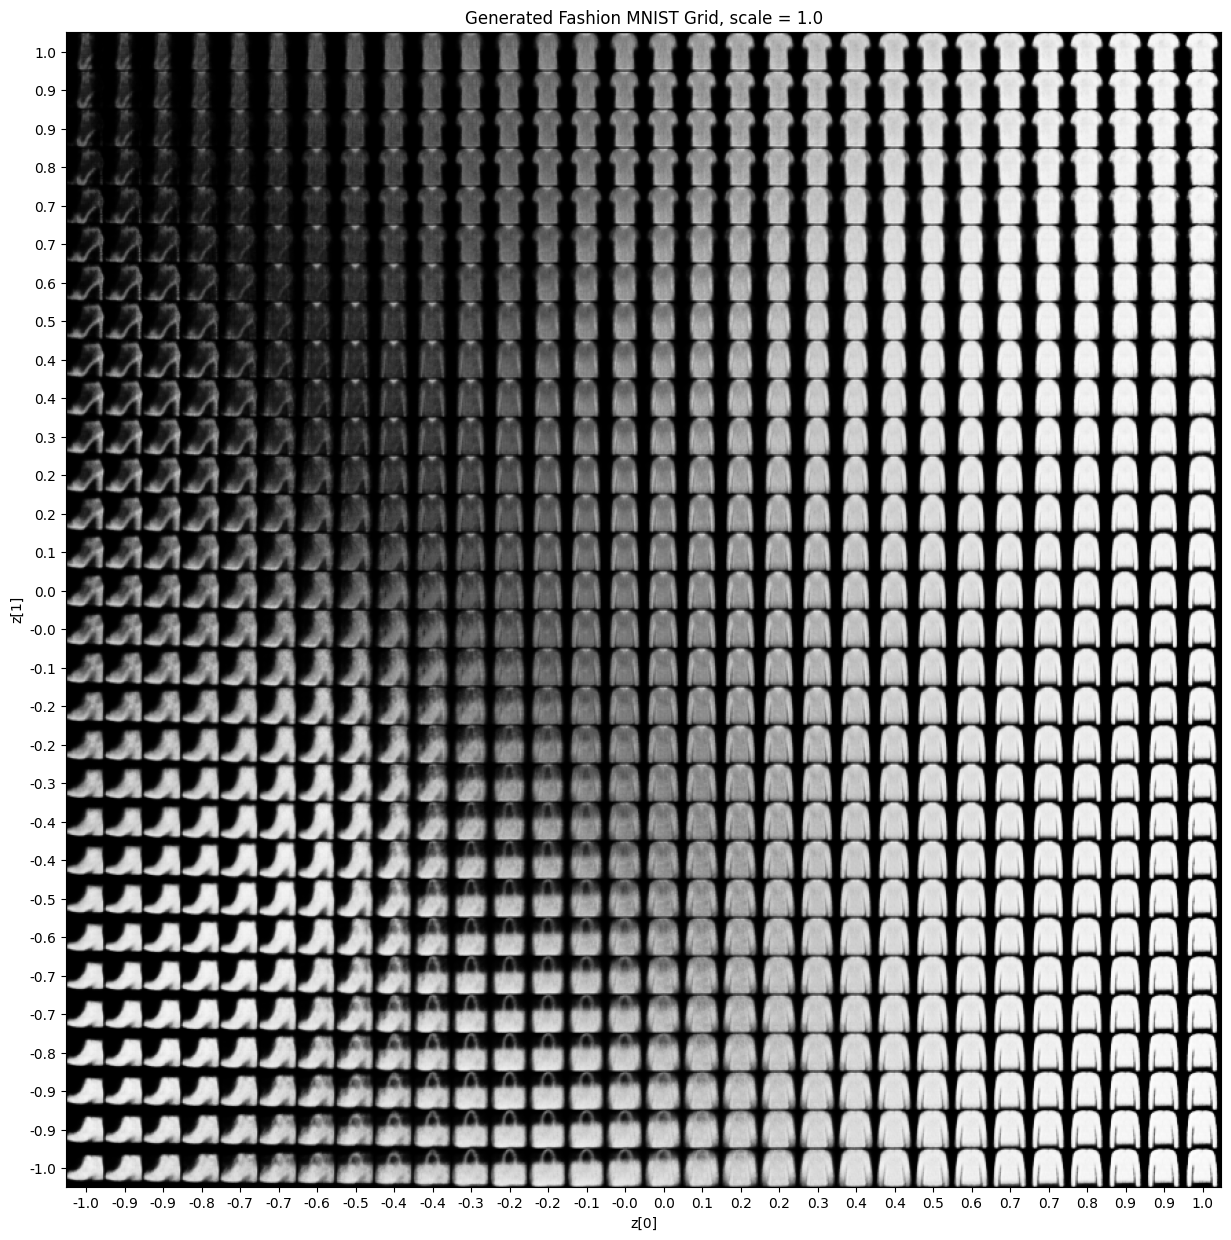

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def plot_latent_space(vae, n=30, figsize=15, scale=1.0):
    digit_size = 28
    figure = np.zeros((digit_size * n, digit_size * n))

    latent_dim = vae.decoder.input_shape[-1]

    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = np.zeros((1, latent_dim))
            z_sample[0, 0] = xi

            if latent_dim > 1:
                z_sample[0, 1] = yi

            x_decoded = vae.decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)

            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = digit

    plt.figure(figsize=(figsize, figsize))

    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)

    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)

    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)

    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.title(f"Generated Fashion MNIST Grid, scale = {scale}")

    plt.imshow(figure, cmap="Greys_r")
    plt.show()


plot_latent_space(vae, scale=1.0)

### Generated Grid Observation

The generated images show Fashion MNIST-like shapes. Since `latent_dim = 3`, the grid varies `z[0]` and `z[1]`, while `z[2]` is fixed at 0.

The generated grid gives a useful 2D slice of the 3D latent space. Although it does not show every possible variation from all three dimensions, it helps show how the decoder changes the generated images as the latent values change.

# 6. Direct Latent Space Plot using z_mean

The plot below visualises the first two latent dimensions, `z[0]` and `z[1]`, using `z_mean`.

`z_mean` is used instead of the sampled latent vector `z` because `z_mean` gives a more stable representation of each image. The sampled `z` includes random noise from the VAE sampling process.

Since this model uses `latent_dim = 3`, this plot only shows the first two dimensions of the full 3D latent space.

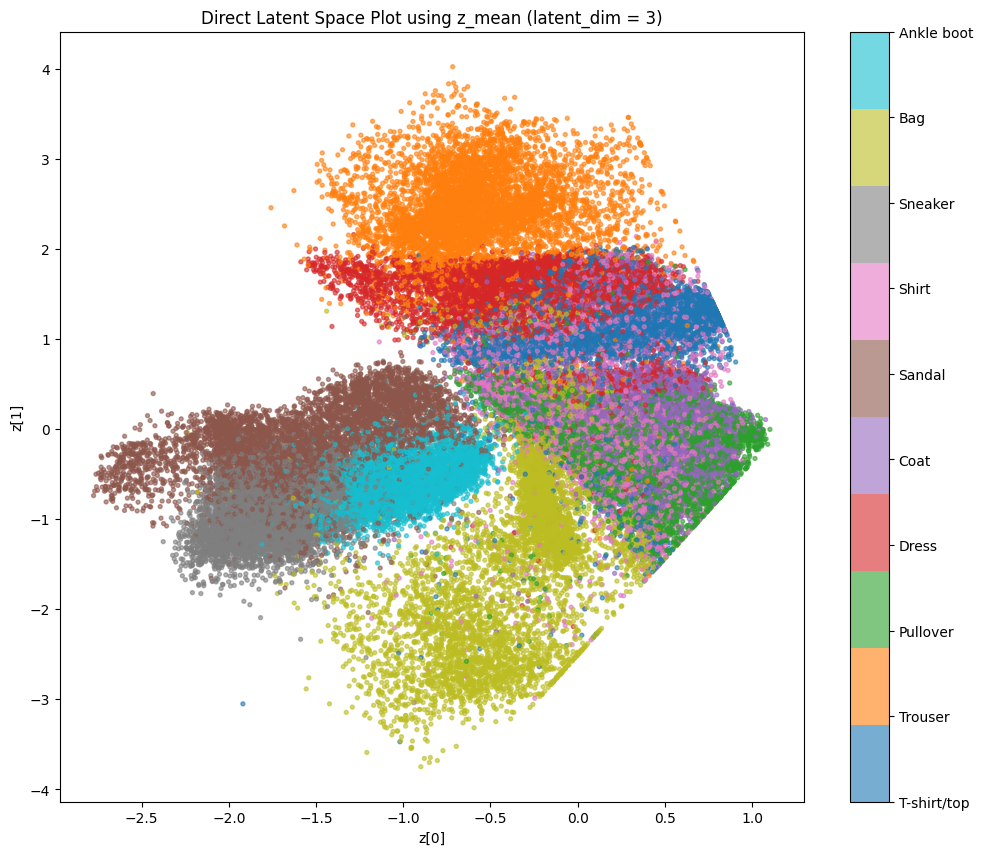

In [22]:
# Load Fashion MNIST for latent space plotting
(x_train_plot, y_train_plot), _ = tf.keras.datasets.fashion_mnist.load_data()
x_train_plot = np.expand_dims(x_train_plot, -1).astype("float32") / 255

fashion_class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

# Extract z_mean
z_mean_plot, _, _ = vae.encoder.predict(x_train_plot, verbose=0)

plt.figure(figsize=(12, 10))

scatter = plt.scatter(
    z_mean_plot[:, 0],
    z_mean_plot[:, 1],
    c=y_train_plot,
    cmap="tab10",
    s=8,
    alpha=0.6
)

cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels([fashion_class_names[i] for i in range(10)])

plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.title("Direct Latent Space Plot using z_mean (latent_dim = 3)")
plt.show()

### Direct Latent Space Observation

The `z[0]`–`z[1]` plot shows several broad class-related regions.

Trouser forms a relatively distinctive region, while footwear and bag-related classes also occupy recognisable parts of the latent space. In contrast, T-shirt/top, Pullover, Dress, Coat, and Shirt overlap substantially in the central regions.

This shows that the first two latent dimensions contain useful class-related structure, but they do not clearly separate all 10 Fashion MNIST categories.

# 7. Pairwise Latent Space Projections

Since the selected model uses `latent_dim = 3`, plotting only `z[0]` against `z[1]` may not show the full latent structure.

To check whether overlapping classes separate along the third dimension, three pairwise projections are shown:

- `z[0]` vs `z[1]`
- `z[0]` vs `z[2]`
- `z[1]` vs `z[2]`

This helps determine whether class overlap is genuine or only caused by viewing the 3D latent space from one 2D angle.

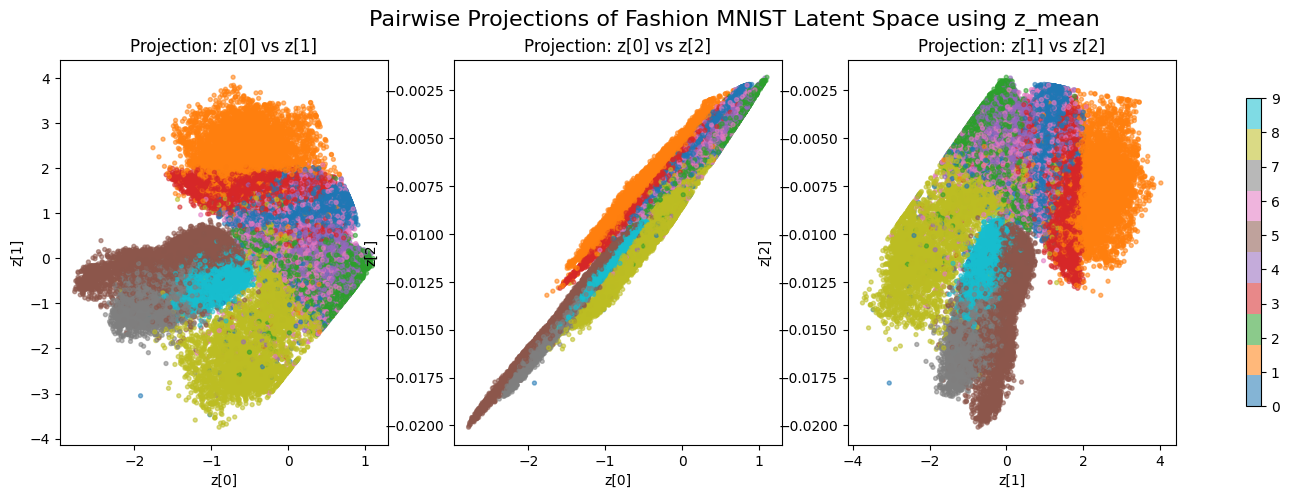

In [23]:
# Pairwise latent space projections for latent_dim = 3

z_mean_plot, _, _ = vae.encoder.predict(x_train_plot, verbose=0)

projection_pairs = [(0, 1), (0, 2), (1, 2)]

plt.figure(figsize=(18, 5))

for i, (dim1, dim2) in enumerate(projection_pairs):
    plt.subplot(1, 3, i + 1)

    scatter = plt.scatter(
        z_mean_plot[:, dim1],
        z_mean_plot[:, dim2],
        c=y_train_plot,
        cmap="tab10",
        s=8,
        alpha=0.55
    )

    plt.xlabel(f"z[{dim1}]")
    plt.ylabel(f"z[{dim2}]")
    plt.title(f"Projection: z[{dim1}] vs z[{dim2}]")

plt.colorbar(scatter, ax=plt.gcf().axes, ticks=range(10), shrink=0.8)
plt.suptitle("Pairwise Projections of Fashion MNIST Latent Space using z_mean", fontsize=16)
plt.show()

### Pairwise Projection Observation

The `z[0]`–`z[1]` projection contains most of the visible latent-space variation and shows several class-related regions.

The `z[0]`–`z[2]` and `z[1]`–`z[2]` projections form very narrow bands because `z[2]` changes very little across the dataset. Therefore, the third dimension does not provide substantial additional class separation in the fully trained main model.

This result is consistent with the violin statistics, where `z[2]` has a standard deviation of only approximately `0.0041`. The main model therefore behaves largely like an effective two-dimensional latent representation despite being configured with `latent_dim = 3`.

# 8. t-SNE Cluster Plot using z_mean

The direct latent space plot only shows `z[0]` and `z[1]`. Since this model uses `latent_dim = 3`, t-SNE is used to reduce the full 3-dimensional `z_mean` vectors into two dimensions.

This helps visualise the overall class structure learned by the VAE across all three latent dimensions.

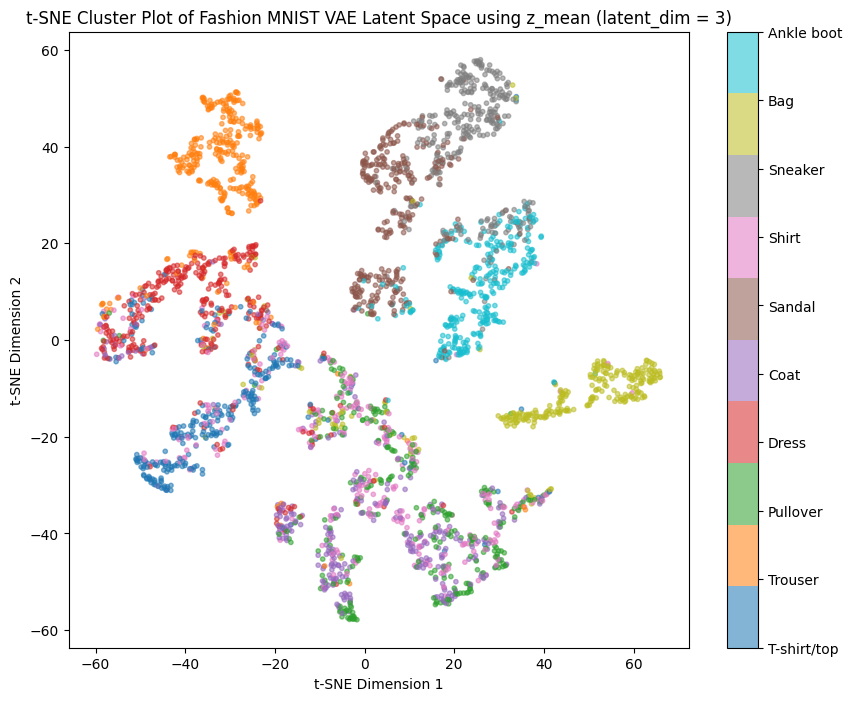

In [24]:
from sklearn.manifold import TSNE

# Use a subset to reduce computation time
num_samples = 3000

x_subset = x_train_plot[:num_samples]
y_subset = y_train_plot[:num_samples]

# Extract stable latent representations using z_mean
z_mean_subset, _, _ = vae.encoder.predict(x_subset, verbose=0)

# Apply t-SNE to the 3D z_mean vectors
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

z_tsne = tsne.fit_transform(z_mean_subset)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    z_tsne[:, 0],
    z_tsne[:, 1],
    c=y_subset,
    cmap="tab10",
    s=10,
    alpha=0.55
)

cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels([fashion_class_names[i] for i in range(10)])

plt.title("t-SNE Cluster Plot of Fashion MNIST VAE Latent Space using z_mean (latent_dim = 3)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

### t-SNE Observation

The t-SNE plot forms several local class groups. Trouser, Bag, and some footwear categories appear more clearly separated, while T-shirt/top, Pullover, Dress, Coat, and Shirt remain more strongly mixed.

This is consistent with the direct latent-space plot: distinctive silhouettes are easier to organise, while visually similar upper-body categories share overlapping latent representations.

Because `z[2]` is nearly inactive in the fully trained model, most of the structure used by t-SNE comes from `z[0]` and `z[1]`.

t-SNE emphasises local neighbourhoods and can distort global distances, so this plot should be interpreted together with the direct and pairwise latent-space plots.

# 9. Violin Plot of latent_dim = 3

A violin plot is used to check how the three latent dimensions are distributed.

Since the VAE uses KL loss, the latent values are expected to be centred around 0. Therefore, being centred around 0 is normal. The more important thing to check is the spread of each latent dimension.

If a dimension has a wider spread, it means the model is using that dimension to capture variation in the data. If a dimension is very narrow and close to 0, it may mean that the dimension is not being used much.

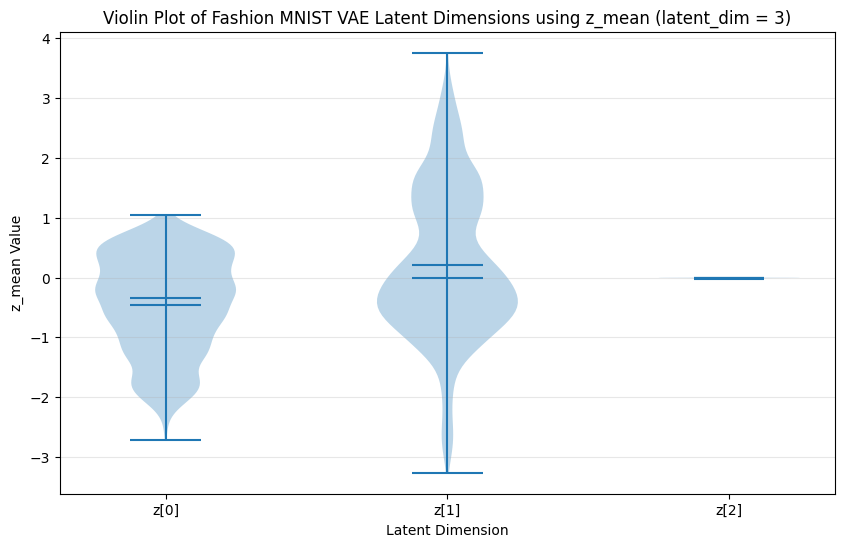

In [25]:
plt.figure(figsize=(10, 6))

data_to_plot = [z_mean_subset[:, i] for i in range(z_mean_subset.shape[1])]

plt.violinplot(
    data_to_plot,
    showmeans=True,
    showmedians=True
)

plt.xticks(
    ticks=np.arange(1, z_mean_subset.shape[1] + 1),
    labels=[f"z[{i}]" for i in range(z_mean_subset.shape[1])]
)

plt.title("Violin Plot of Fashion MNIST VAE Latent Dimensions using z_mean (latent_dim = 3)")
plt.xlabel("Latent Dimension")
plt.ylabel("z_mean Value")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [26]:
for i in range(z_mean_subset.shape[1]):
    print(
        f"z[{i}] mean: {z_mean_subset[:, i].mean():.4f}, "
        f"std: {z_mean_subset[:, i].std():.4f}, "
        f"min: {z_mean_subset[:, i].min():.4f}, "
        f"max: {z_mean_subset[:, i].max():.4f}"
    )

z[0] mean: -0.4508, std: 0.8204, min: -2.7080, max: 1.0449
z[1] mean: 0.2148, std: 1.2464, min: -3.2611, max: 3.7555
z[2] mean: -0.0088, std: 0.0041, min: -0.0198, max: -0.0020


### Violin Plot Observation

The violin plot shows how the three latent dimensions are distributed after training the main `latent_dim = 3` VAE.

Most values are centred around 0, which is expected because the VAE uses KL loss to regularise the latent space.

The standard deviation values show that `z[0]` and `z[1]` have meaningful spread, meaning they are actively used by the model. However, `z[2]` has a very small spread, suggesting that the third latent dimension is used much less after full training.

This shows that even though `latent_dim = 3` was selected as a compact setting, the trained model mainly relies on two stronger latent dimensions. This motivates the additional analysis in Experiment 5, where the improved architecture and latent dimension variation matrices are used to better study how each dimension contributes to generation.

# Experiment 3: Changing the Scale Value

The `scale` value controls the range of latent values used in `plot_latent_space(vae)`.

Since this VAE has `latent_dim = 3`, the grid varies `z[0]` and `z[1]`, while `z[2]` is fixed at 0. Therefore, the scale experiment shows how changing the range of this 2D slice affects image generation.

The tested scale values are:

- `scale = 1.0`
- `scale = 2.0`
- `scale = 3.0`

# 1. Scale = 2.0

With `scale = 2.0`, the decoder explores a wider region of the latent space. This can produce more variety while still keeping many images recognisable.

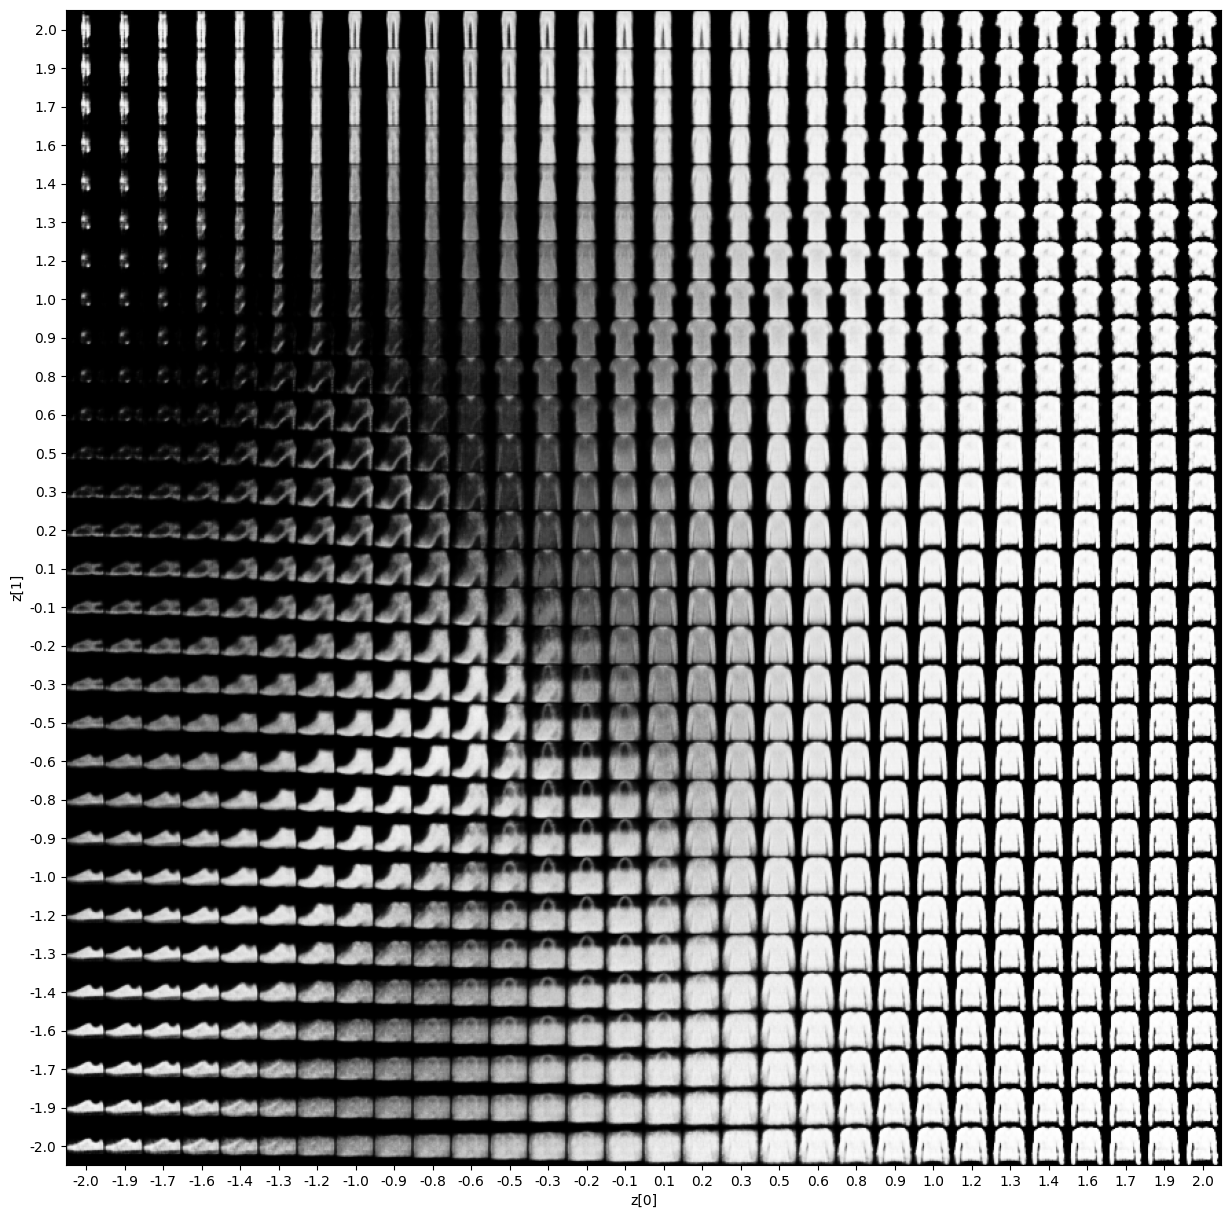

In [27]:
import numpy as np
import matplotlib.pyplot as plt

def plot_latent_space(vae, n=30, figsize=15, scale=1.0):
    # Size of each Fashion MNIST image
    digit_size = 28

    # Create an empty canvas to store all generated images
    figure = np.zeros((digit_size * n, digit_size * n))

    # Get decoder latent dimension automatically
    latent_dim = vae.decoder.input_shape[-1]

    # Create values for z[0] and z[1]
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            # Create latent vector with correct number of inputs
            # For latent_dim > 2, the extra latent values are kept as 0
            z_sample = np.zeros((1, latent_dim))
            z_sample[0, 0] = xi

            if latent_dim > 1:
                z_sample[0, 1] = yi

            # Generate image using decoder
            x_decoded = vae.decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)

            # Place generated image into the grid
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = digit

    # Plot the full image grid
    plt.figure(figsize=(figsize, figsize))

    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)

    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)

    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

plot_latent_space(vae, scale=2.0)

### Scale = 2.0 Observation

The generated images show more variety compared to `scale = 1.0`. More Fashion MNIST-like categories can be observed, including shoes, bags, tops, dresses, and trouser-like shapes. Some images near the edges become slightly distorted, but the overall quality remains acceptable.

# 2. Scale = 3.0

With `scale = 3.0`, the decoder samples from an even wider region of the latent space. This may increase variety, but it can also generate distorted images if the sampled points are far from well-learned regions.

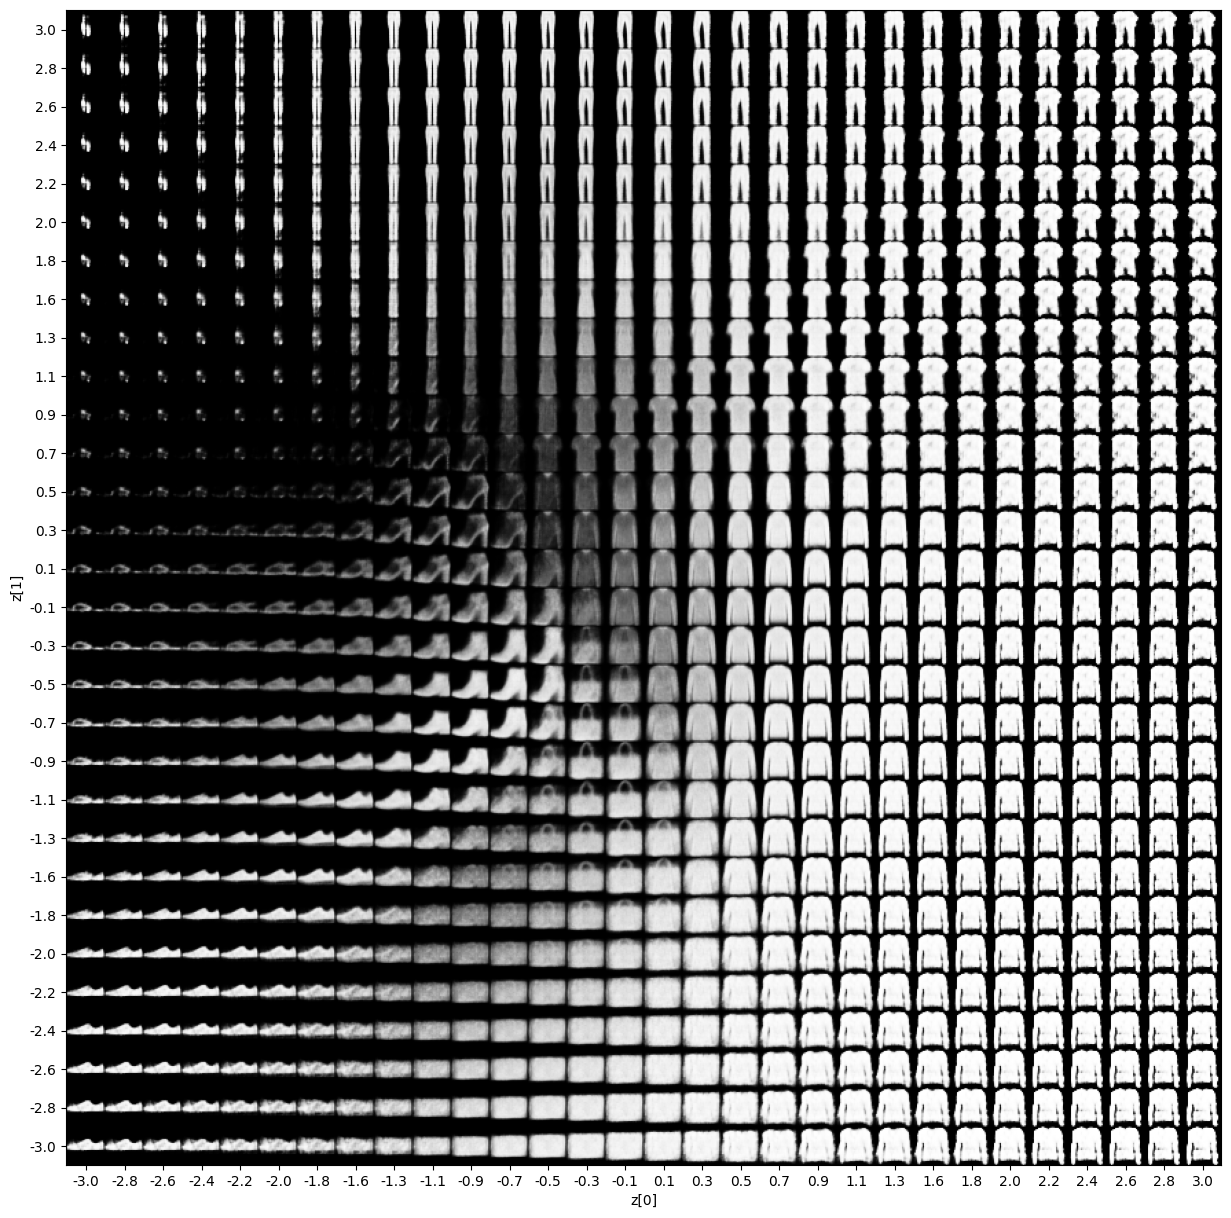

In [28]:
import numpy as np
import matplotlib.pyplot as plt

def plot_latent_space(vae, n=30, figsize=15, scale=1.0):
    # Size of each Fashion MNIST image
    digit_size = 28

    # Create an empty canvas to store all generated images
    figure = np.zeros((digit_size * n, digit_size * n))

    # Get decoder latent dimension automatically
    latent_dim = vae.decoder.input_shape[-1]

    # Create values for z[0] and z[1]
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            # Create latent vector with correct number of inputs
            # For latent_dim > 2, the extra latent values are kept as 0
            z_sample = np.zeros((1, latent_dim))
            z_sample[0, 0] = xi

            if latent_dim > 1:
                z_sample[0, 1] = yi

            # Generate image using decoder
            x_decoded = vae.decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)

            # Place generated image into the grid
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = digit

    # Plot the full image grid
    plt.figure(figsize=(figsize, figsize))

    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)

    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)

    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

plot_latent_space(vae, scale=3.0)

### Scale = 3.0 Observation

The generated images show wider variation, but many outputs near the outer regions become noisier, stretched, or less realistic. This suggests that sampling too far from the centre of the latent space can reduce image quality.

# 3. Scale Experiment Conclusion

Changing the scale affects both variety and image quality. With `scale = 1.0`, the generated images are more stable but less varied. With `scale = 2.0`, the model explores a wider region of the latent space and can produce more varied images while still maintaining reasonable quality. With `scale = 3.0`, the variety increases further, but more images may become distorted.

Based on visual inspection of the generated grids in this run, `scale = 2.0` appears to provide the best balance between image variety and recognisability among the tested values.

# Experiment 4: Generate All Fashion MNIST Classes

This experiment checks whether the `latent_dim = 3` VAE decoder can generate all 10 Fashion MNIST classes.

The method used is:

1. Encode all Fashion MNIST training images into the latent space using `z_mean`.
2. Find the average latent vector for each class.
3. Decode each class-centre latent vector.
4. Display one generated image for each class.

The Fashion MNIST classes are:

| Label | Class |
|---|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

# 1. Class-Centre Generation

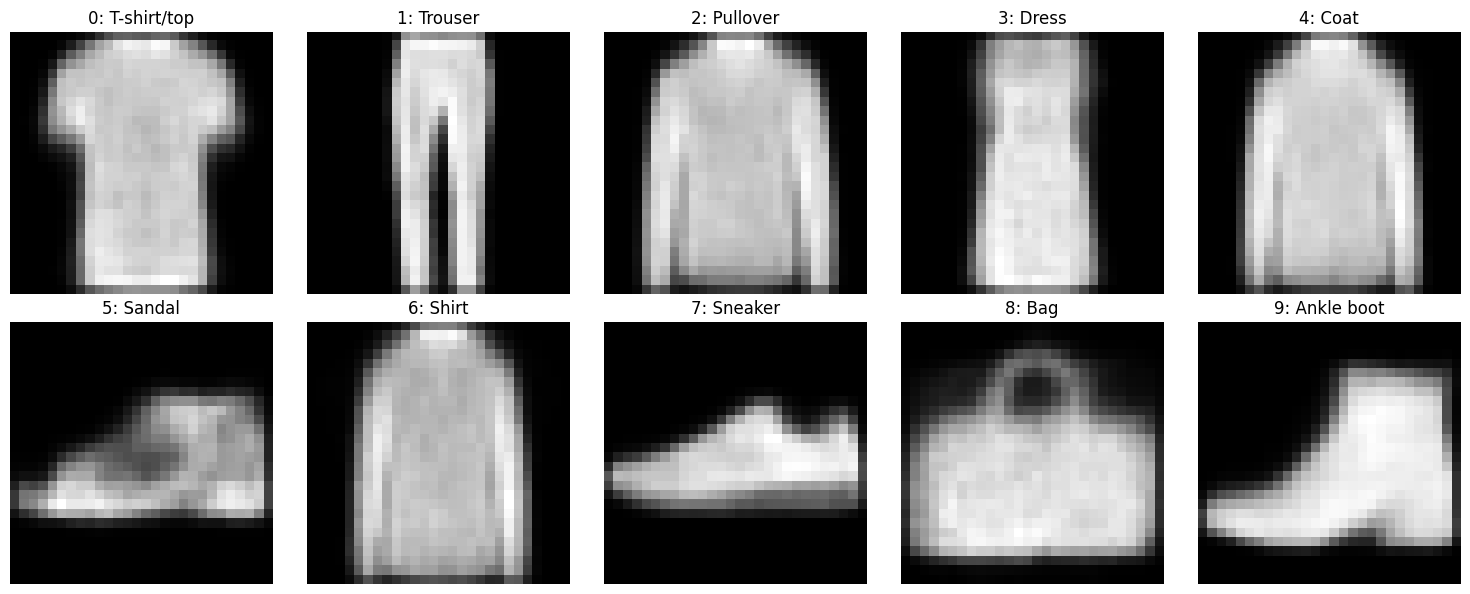

In [29]:
fashion_class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

# Load and prepare Fashion MNIST
(x_train_class, y_train_class), _ = tf.keras.datasets.fashion_mnist.load_data()
x_train_class = np.expand_dims(x_train_class, -1).astype("float32") / 255

# Encode images using z_mean
z_mean_class, _, _ = vae.encoder.predict(x_train_class, verbose=0)

decoded_images = []

for class_id in range(10):
    class_vectors = z_mean_class[y_train_class == class_id]
    class_centre = class_vectors.mean(axis=0)

    decoded = vae.decoder.predict(class_centre.reshape(1, -1), verbose=0)
    decoded_image = decoded[0].reshape(28, 28)

    decoded_images.append(decoded_image)

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(decoded_images[i], cmap="gray")
    plt.title(f"{i}: {fashion_class_names[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Class-Centre Generation Observation

The decoder produced one Fashion MNIST-like prototype for each of the 10 class-centre latent vectors.

Trouser, Sneaker, and Ankle boot are relatively recognisable because they have distinctive silhouettes. T-shirt/top, Pullover, Dress, Coat, and Shirt produce more similar upper-body shapes and are therefore harder to distinguish clearly. Some categories, such as Sandal and Bag, are generated less clearly than their original class examples.

The result shows that the latent representation contains class-related information for all 10 labels, but the quality and distinctiveness of the generated prototypes vary between classes.

# 2.  Bias / Limitation Observation

The model appears weaker at separating visually similar upper-body clothing classes such as pullover, coat, shirt, and T-shirt/top. If some classes are not generated clearly, this suggests a possible limitation or bias in the decoder’s learned latent representation.

Class-centre decoding is label-informed because the known Fashion MNIST labels are used to calculate an average latent vector for each class. It demonstrates that class-related prototypes exist in the learned representation, but it does not prove that random latent sampling generates all 10 classes equally or without bias.

### Experimental Limitation

The latent-dimension comparison was based on one training run for each tested value. VAE results can vary because of random weight initialisation, random sampling and mini-batch order.

A more rigorous experiment would train each latent dimension several times using different random seeds, then compare the average reconstruction loss and standard deviation. Therefore, the selected `latent_dim = 3` should be described as a balanced and interpretable choice from this experiment, rather than a universally optimal latent dimension.

# 3. Save the weights

In [30]:
vae.save_weights("vae_fashion_latent3.weights.h5")
encoder.save_weights("encoder_fashion_latent3.weights.h5")
decoder.save_weights("decoder_fashion_latent3.weights.h5")

# Conclusion

In this notebook, different latent dimensions were compared before selecting the main VAE model. The comparison tested `latent_dim = 2`, `3`, `4`, and `5` using reconstruction loss, active latent dimensions, and violin plots.

Based on the comparison, `latent_dim = 3` was selected as the main setting because it gave a compact and interpretable latent space, with all three dimensions active in the quick comparison. Although `latent_dim = 4` achieved the lowest reconstruction loss in the quick comparison, `latent_dim = 3` was chosen because it had a fully active latent space and was easier to analyse.

The main `latent_dim = 3` model was then trained on the full Fashion MNIST dataset. The direct latent plot, pairwise projections and t-SNE plot were used to examine class structure.

The violin plot showed that `z[0]` and `z[1]` were actively used, while `z[2]` became nearly inactive after full training. Therefore, although three dimensions were active in the quick comparison, the fully trained main model relied mainly on two stronger dimensions. This limitation motivated the improved architecture and more detailed latent analysis in Experiment 5.

The generated image grid showed a 2D slice of the 3D latent space by varying `z[0]` and `z[1]` while freezing `z[2]` at 0. The scale experiment showed that `scale = 2.0` gave the best balance between image diversity and image quality among the tested scale values.

The class-centre generation experiment showed that the decoder could generate Fashion MNIST-like images for all 10 classes, although visually similar clothing categories such as T-shirt/top, Pullover, Coat, and Shirt remained harder to distinguish.

Overall, `latent_dim = 3` was selected as a compact and interpretable experimental setting. The full training results also show that configuring three latent dimensions does not guarantee that all three will remain actively used.